TP3 - Jann Luna Pedro - Pandas - 25/11/2025

Dans ce troisième TP, nous allons travailler avec certaines fonctions d'organisation des données et des tableaux à l'aide de la bibliothèque Pandas.

In [69]:
import numpy
import pandas
import matplotlib.pyplot

In [70]:
#1

#Calcul du nombre  de voix obtenues par le candidat 

data_presidentielles = pandas.read_csv("elections-presidentielles-2017-1ertour.csv",  sep =';')
# print(data_presidentielles)

df_1 = pandas.DataFrame(data_presidentielles)
voix_m = df_1['MÉLENCHON Jean-Luc']

total_voix = numpy.sum(voix_m)

print(total_voix)
print(f'le nombre total de votes était de {total_voix}')

210548
le nombre total de votes était de 210548


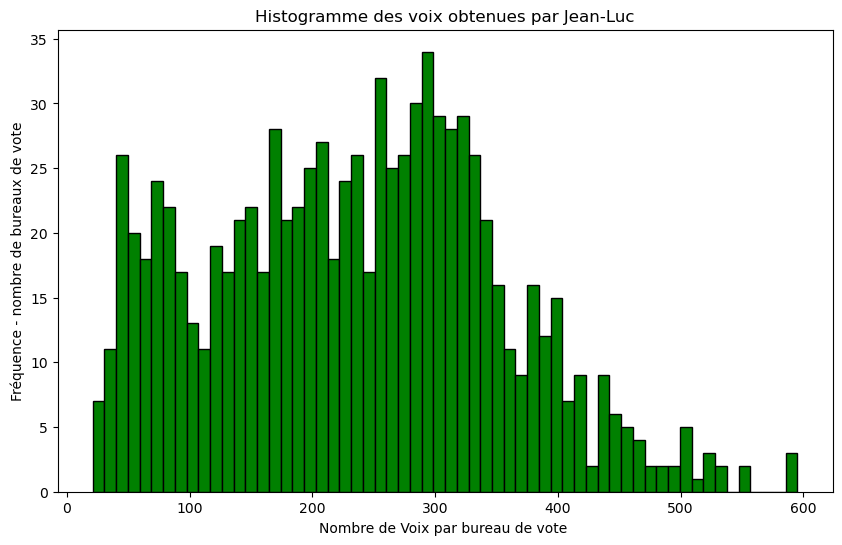

In [71]:
#2

# l'histogramme pour visualiser la répartition des voix de Méchelon.

y = voix_m
fig = matplotlib.pyplot.figure(figsize=(10, 6))

#en utilisant la fonction apprise dans TP2:
matplotlib.pyplot.hist(y, bins=60, color='g', edgecolor = 'black')
matplotlib.pyplot.title("Histogramme des voix obtenues par Jean-Luc") 
matplotlib.pyplot.xlabel('Nombre de Voix par bureau de vote ')
matplotlib.pyplot.ylabel('Fréquence - nombre de bureaux de vote')

#show histo
matplotlib.pyplot.show()

In [72]:
#3

#On va regrouper les données par arrondissement
#pour compter le nombre de bureaux de vote dans chacun.

groupes_compter = df_1.groupby('NUM_ARROND')['ID_BVOTE']

print(groupes_compter)

#comptage
bureaux_par_arr = groupes_compter.count()

print(bureaux_par_arr)
print("Le résultat montre le total des bureaux de vote par arrondissement.")

NUM_ARROND
1     10
2     10
3     15
4     14
5     25
6     22
7     25
8     18
9     27
10    39
11    55
12    64
13    71
14    57
15    95
16    68
17    67
18    68
19    70
20    76
Name: ID_BVOTE, dtype: int64
Le résultat montre le total des bureaux de vote par arrondissement.


In [73]:
#4

#Extraction des voix obtenues par Hamon pour bureau de vote.

#colonnes ID_BVOTE et HAMON Benoît
voix_ha = df_1[['ID_BVOTE', 'HAMON Benoît']]

print(voix_ha.head())

print('Les données pour nombre de voix obtenues par Hamon dans bureau de vote')

  ID_BVOTE  HAMON Benoît
0    15-49           107
1    15-51           126
2    15-77            90
3    16-42            29
4    16-55            27
Les données pour nombre de voix obtenues par Hamon dans bureau de vote


In [74]:
#5

#diviser le df par arrondissement
grupes_arr = df_1.groupby('NUM_ARROND')

#somme (nouveau df)
resultats_par_arr = grupes_arr.sum()

# print(type(resultats_par_arr))

# affichage (premières lignes)
print(resultats_par_arr.head())
print("Le tableau montre le total des voix obtenues par candidat dans chaque arrondissement.")

                                                     ID_BVOTE  \
NUM_ARROND                                                      
1                             1-81-51-61-71-101-91-21-41-11-3   
2                             2-12-22-102-42-32-72-82-52-62-9   
3           3-13-23-133-93-73-153-43-113-83-53-63-33-123-1...   
4             4-94-124-64-14-54-34-134-84-114-24-104-44-74-14   
5           5-75-165-235-45-65-115-155-255-175-95-215-15-3...   

                                                      SCRUTIN  ANNEE  TOUR  \
NUM_ARROND                                                                   
1           PrésidentiellePrésidentiellePrésidentiellePrés...  20170    10   
2           PrésidentiellePrésidentiellePrésidentiellePrés...  20170    10   
3           PrésidentiellePrésidentiellePrésidentiellePrés...  30255    15   
4           PrésidentiellePrésidentiellePrésidentiellePrés...  28238    14   
5           PrésidentiellePrésidentiellePrésidentiellePrés...  50425    25  

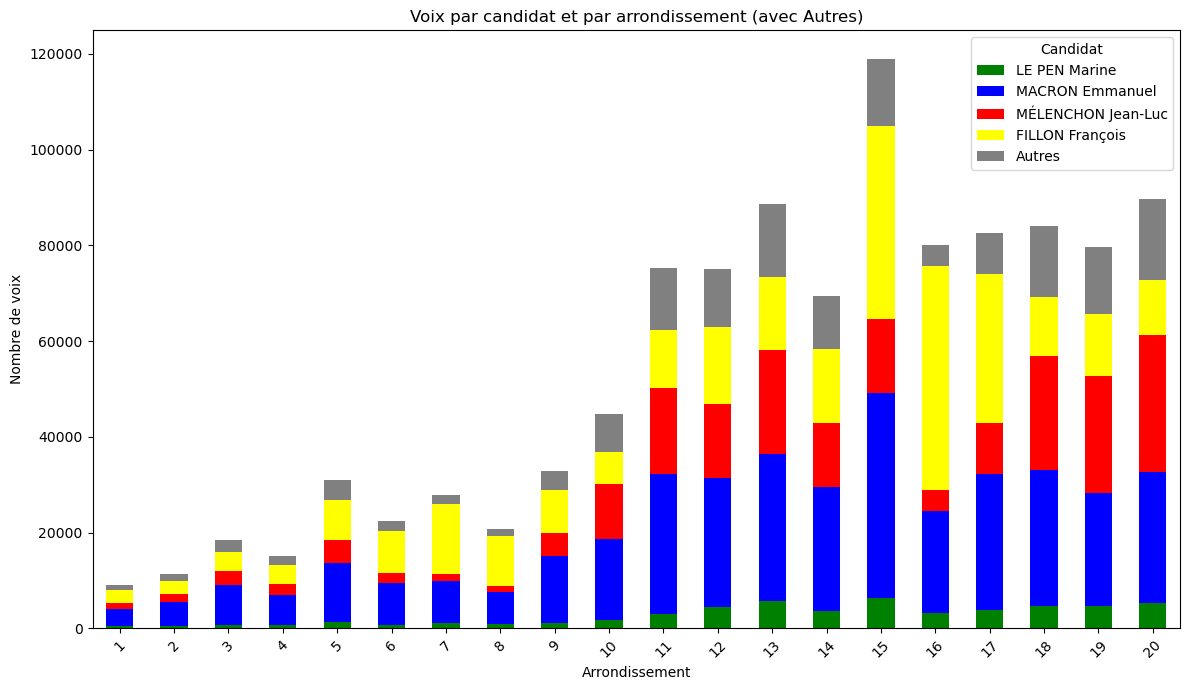

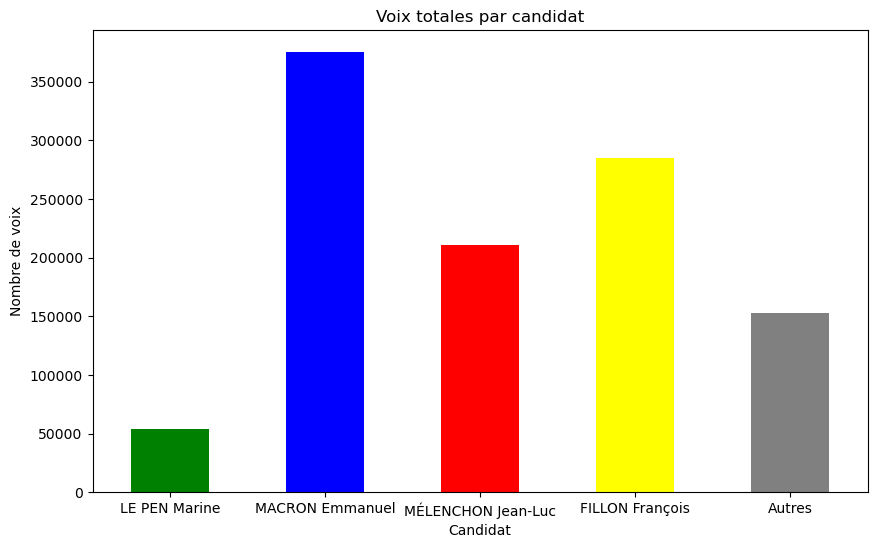

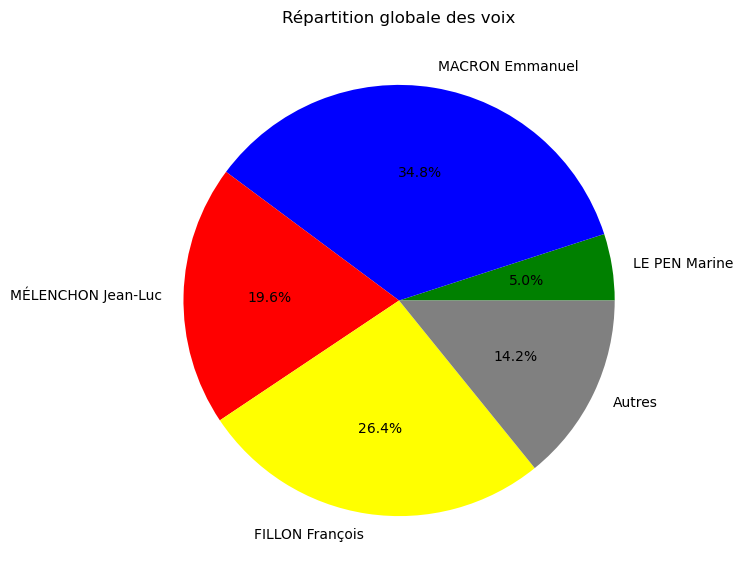

In [85]:
#6

# le objective est de visualiser la répartition des voix.

# Les résultats des quatre candidats principaux et de la catégorie 'Autres' sont montrés
# par un diagramme en barres empiléeset un camembert.

#candidats et couleurs
candidats = ['LE PEN Marine', 'MACRON Emmanuel', 'MÉLENCHON Jean-Luc', 'FILLON François']
couleurs = ['green', 'blue', 'red', 'yellow', 'gray'] 

#autres
tous_candidats_cols = df_1.columns[16:27].tolist() 

# diviser, sélectionner et sommer (data)
# Calcul des totaux globaux pour le Top 4 et les Autres

df_par_candidat = df_1[tous_candidats_cols].sum()
somme_top4 = df_par_candidat[candidats].sum()
somme_tous = df_par_candidat.sum()
somme_autres = somme_tous - somme_top4

#top 4 + autres
series_autres = pandas.Series([somme_autres], index=['Autres'])
globale = pandas.concat([df_par_candidat[candidats], series_autres])

#données par arrondissement
df_par_arrond = df_1.groupby('NUM_ARROND')[tous_candidats_cols].sum()
df_total_tous_arrond = df_par_arrond.sum(axis=1) 
df_total_top4_arrond = df_par_arrond[candidats].sum(axis=1)
df_autres_arrond = df_total_tous_arrond - df_total_top4_arrond
df_comparaison_avec_autres = df_par_arrond[candidats].copy()
df_comparaison_avec_autres['Autres'] = df_autres_arrond

#Par arrondissement
matplotlib.pyplot.figure(figsize=(12, 7))
axe_arrond = matplotlib.pyplot.gca() 
df_comparaison_avec_autres.plot(kind='bar', stacked=True, color=couleurs, ax=axe_arrond)
axe_arrond.set_title("Voix par candidat et par arrondissement (avec Autres)")
axe_arrond.set_ylabel("Nombre de voix")
axe_arrond.set_xlabel("Arrondissement")
axe_arrond.legend(title='Candidat')
matplotlib.pyplot.xticks(rotation=45) 
matplotlib.pyplot.tight_layout()
matplotlib.pyplot.show()

#répresentation en barres
matplotlib.pyplot.figure(figsize=(10, 6))
axe_barres = matplotlib.pyplot.gca() 
globale.plot(kind='bar', color=couleurs, ax=axe_barres)#barres
axe_barres.set_title("Voix totales par candidat")
axe_barres.set_ylabel("Nombre de voix")
axe_barres.set_xlabel("Candidat")
matplotlib.pyplot.xticks(rotation=0) 
matplotlib.pyplot.show()

#répresentation en camembert 
matplotlib.pyplot.figure(figsize=(7, 7))
axe_camembert = matplotlib.pyplot.gca() 
globale.plot(kind='pie', autopct='%1.1f%%', colors=couleurs, ax=axe_camembert)#camembert 
axe_camembert.set_title("Répartition globale des voix")
axe_camembert.set_ylabel("") 
matplotlib.pyplot.show()

Réponse 6:

Le diagramme en barres est la meilleure représentation pour cette comparaison.

Il permet de comparer directement le nombre absolu de voix obtenues par chaque candidat. Le camembert, bien que montrant les proportions, est moins efficace pour voir des différences de taille entre les parts qui sont proches.

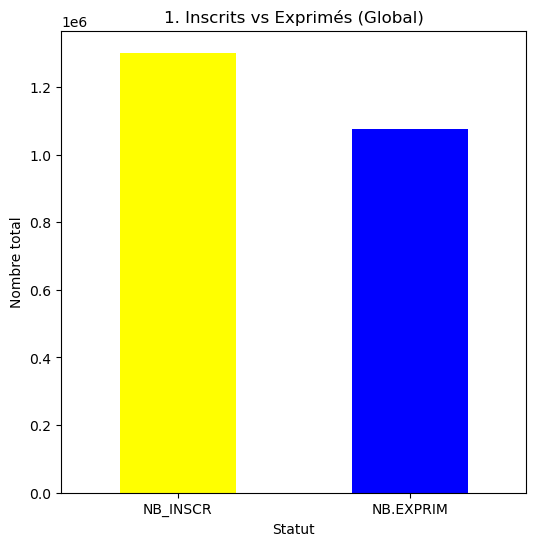

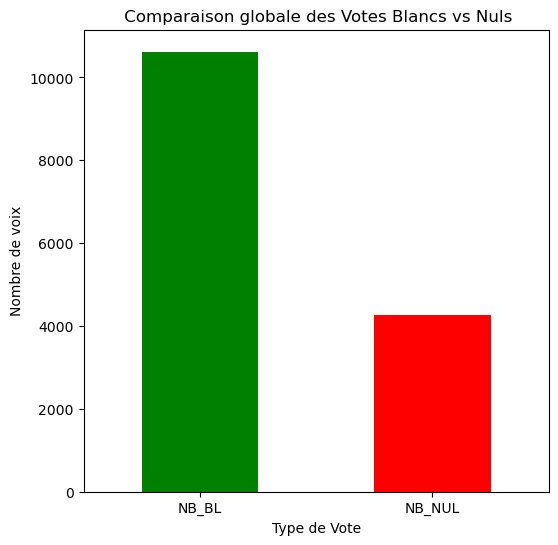

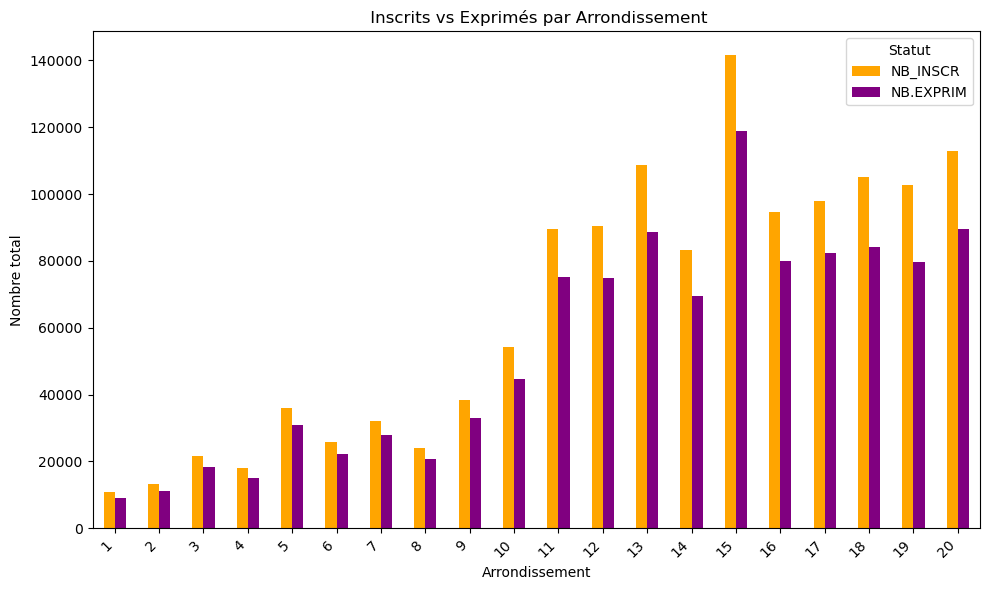

In [81]:
#7

#Inscrits vs Exprimés
global_pools = df_1[['NB_INSCR', 'NB.EXPRIM']].sum()

matplotlib.pyplot.figure(figsize=(6, 6))
axe1 = matplotlib.pyplot.gca()
global_pools.plot(kind='bar', color=['yellow', 'blue'], ax=axe1)
axe1.set_title("1. Inscrits vs Exprimés (Global)")
axe1.set_ylabel("Nombre total")
axe1.set_xlabel("Statut")
matplotlib.pyplot.xticks(rotation=0)
matplotlib.pyplot.show()


#Comparaison des Votes Perdus (Global)

wasted_votes_globaux = df_1[['NB_BL', 'NB_NUL']].sum()
matplotlib.pyplot.figure(figsize=(6, 6))
axe3 = matplotlib.pyplot.gca()
wasted_votes_globaux.plot(kind='bar', color=['green','red'], ax=axe3)
axe3.set_title(" Comparaison globale des Votes Blancs vs Nuls")
axe3.set_ylabel("Nombre de voix")
axe3.set_xlabel("Type de Vote")
matplotlib.pyplot.xticks(rotation=0)
matplotlib.pyplot.show()


#Inscrits vs Exprimés par Arrondissement
df_inscrits_exprimes = df_1.groupby('NUM_ARROND')[['NB_INSCR', 'NB.EXPRIM']].sum()

matplotlib.pyplot.figure(figsize=(10, 6))
axe3 = matplotlib.pyplot.gca()
df_inscrits_exprimes.plot(kind='bar', ax=axe3, color=['orange', 'purple'])
axe3.set_title(" Inscrits vs Exprimés par Arrondissement")
axe3.set_ylabel("Nombre total")
axe3.set_xlabel("Arrondissement")
axe3.legend(title='Statut')
matplotlib.pyplot.xticks(rotation=45, ha='right')
matplotlib.pyplot.tight_layout()
matplotlib.pyplot.show()


